# 06. Evaluación Rigurosa del Baseline — IBM TabFormer
**Unidad 1:** Detección de Fraude en Transacciones con Tarjeta de Crédito  
**Dataset:** Conjunto de Prueba Temporal (`test_split.parquet`, Año 2019)  
**Entorno:** Python 3.12 | scikit-learn | Matplotlib | Seaborn

---

### Objetivos del Notebook:
1. Cargar el conjunto de prueba independiente temporal (`test_split.parquet`, correspondiente al año 2019 completo con prevalencia natural de 0.124%).
2. Cargar el preprocesador ajustado y los modelos entrenados (`baseline_logistic_regression.joblib` y `linear_regression_comparison.joblib`).
3. Evaluar exhaustivamente la **Regresión Logística**:
   - Métricas clave: **Precision**, **Recall**, **F1-Score**, **Average Precision (PR-AUC)** y **ROC-AUC**.
   - Matriz de Confusión detallada con conteos de Verdaderos Positivos (TP), Falsos Positivos (FP), Verdaderos Negativos (TN) y Falsos Negativos (FN).
   - Generación de curvas Precision-Recall y ROC.
   - Demostración empírica de la **Paradoja de la Exactitud (Accuracy Paradox)** frente al desbalance real (0.124%).
4. Evaluar la **Regresión Lineal**:
   - Errores continuos: MSE, RMSE, MAE, R².
   - Porcentaje de predicciones anómalas fuera del intervalo probabilístico [0, 1].
   - Justificación formal de por qué la regresión por mínimos cuadrados ordinarios no es adecuada para clasificar fraude.
5. Exportar todas las métricas en `artifacts/evaluation_metrics.json`.


In [1]:
import sys
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR
while not (PROJECT_ROOT / "notebooks").exists() and PROJECT_ROOT.parent != PROJECT_ROOT:
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from notebooks._comun.config import (
    TEST_DATA_FILE,
    PREPROCESSOR_ARTIFACT,
    LOGISTIC_MODEL_ARTIFACT,
    LINEAR_MODEL_ARTIFACT,
    METRICS_ARTIFACT,
    SELECTED_FEATURES,
)
from notebooks._comun.data_utils import (
    load_artifact,
    save_json,
    compute_classification_metrics,
    compute_regression_metrics,
)
print(f"Raíz del proyecto: {PROJECT_ROOT}")


Raíz del proyecto: /home/glender/ProyectosUNi/iaupeu


In [2]:
import polars as pl
import numpy as np
import pandas as pd
import json
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    precision_recall_curve,
    roc_curve,
    ConfusionMatrixDisplay,
    classification_report,
)

# Estilo gráfico
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Carga del Test Set independiente (Prevalencia Natural 2019)
test_df = pl.read_parquet(TEST_DATA_FILE)
if "mcc_category" not in test_df.columns:
    from notebooks._comun.data_utils import categorize_mcc_expr
    test_df = test_df.with_columns(categorize_mcc_expr("MCC"))
print(f"Conjunto de prueba independiente (Año 2019): {test_df.shape[0]:,} transacciones")
print(f"Fraudes reales en prueba: {test_df['is_fraud'].sum():,} ({test_df['is_fraud'].mean()*100:.4f}% prevalencia natural)")

# Carga de artefactos
preprocessor = load_artifact(PREPROCESSOR_ARTIFACT)
log_clf = load_artifact(LOGISTIC_MODEL_ARTIFACT)
lin_reg = load_artifact(LINEAR_MODEL_ARTIFACT)
print("Artefactos cargados exitosamente.")


Conjunto de prueba independiente (Año 2019): 1,639,673 transacciones
Fraudes reales en prueba: 2,033 (0.1240% prevalencia natural)
Artefactos cargados exitosamente.


## 1. Transformación de Características en el Conjunto de Prueba
Aplicamos el preprocesador **sin reajustar (transform)** sobre `test_df`.


In [3]:
X_test_df = test_df.select(SELECTED_FEATURES).to_pandas()
y_test = test_df["is_fraud"].to_numpy()

X_test_trans = preprocessor.transform(X_test_df)
print(f"Matriz X_test transformada: {X_test_trans.shape}")


Matriz X_test transformada: (1639673, 21)


## 2. Evaluación del Baseline Principal: Regresión Logística
Calculamos las predicciones discretas y las probabilidades asociadas a la clase positiva (Fraude).


In [4]:
# Predicciones y probabilidades
y_pred_log = log_clf.predict(X_test_trans)
y_prob_log = log_clf.predict_proba(X_test_trans)[:, 1]

# Cálculo de métricas completas
metrics_log = compute_classification_metrics(y_test, y_pred_log, y_prob_log)

print("=== Métricas de Clasificación — Regresión Logística (Test 2019 Natural) ===")
print(f"Accuracy:           {metrics_log['accuracy']:.4f}")
print(f"Precision:          {metrics_log['precision']:.4f}")
print(f"Recall (Sensib.):   {metrics_log['recall']:.4f}")
print(f"F1-Score:           {metrics_log['f1_score']:.4f}")
print(f"PR-AUC (Avg Prec):  {metrics_log['pr_auc']:.4f}")
print(f"ROC-AUC:            {metrics_log['roc_auc']:.4f}")
print(f"Tasa Falsos Posit.: {metrics_log['false_positive_rate']*100:.2f}%")
print(f"Tasa Falsos Negat.: {metrics_log['false_negative_rate']*100:.2f}%")


=== Métricas de Clasificación — Regresión Logística (Test 2019 Natural) ===
Accuracy:           0.7257
Precision:          0.0032
Recall (Sensib.):   0.7088
F1-Score:           0.0064
PR-AUC (Avg Prec):  0.0050
ROC-AUC:            0.7938
Tasa Falsos Posit.: 27.43%
Tasa Falsos Negat.: 29.12%


## 3. Matriz de Confusión Detallada
Visualizamos la distribución entre Verdaderos Positivos, Falsos Positivos, Verdaderos Negativos y Falsos Negativos.


Verdaderos Negativos (TN - Legítimas detectadas):   1,188,457
Falsos Positivos     (FP - Falsas alarmas):         449,183
Falsos Negativos     (FN - Fraudes no detectados):  592
Verdaderos Positivos (TP - Fraudes interceptados):  1,441


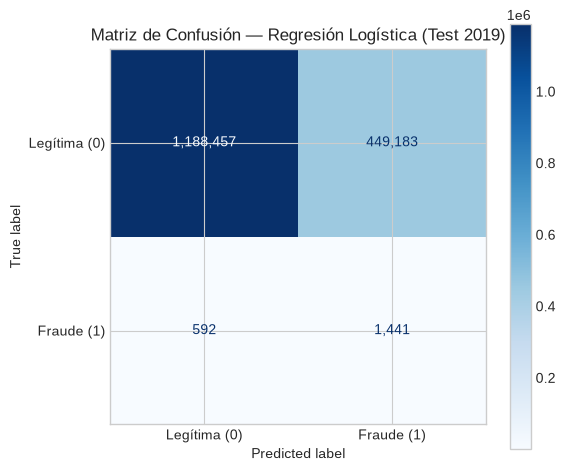

In [5]:
cm = metrics_log["confusion_matrix"]
print(f"Verdaderos Negativos (TN - Legítimas detectadas):   {cm['tn']:,}")
print(f"Falsos Positivos     (FP - Falsas alarmas):         {cm['fp']:,}")
print(f"Falsos Negativos     (FN - Fraudes no detectados):  {cm['fn']:,}")
print(f"Verdaderos Positivos (TP - Fraudes interceptados):  {cm['tp']:,}")

cm_matrix = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_matrix, display_labels=["Legítima (0)", "Fraude (1)"])
disp.plot(cmap="Blues", values_format=",d", ax=ax)
ax.set_title("Matriz de Confusión — Regresión Logística (Test 2019)")
plt.tight_layout()
plt.show()


> ## 4. Análisis Crítico: La Paradoja de la Exactitud (Accuracy Paradox)
>
> 1. En este conjunto de prueba temporal (2019), la prevalencia real y natural de fraude es de apenas **0.124%** (2,033 fraudes en 1,639,673 transacciones).
> 2. Si un modelo trivial o "ingenuo" predijera sistemáticamente `0` (ninguna transacción es fraude), obtendría un **Accuracy del 99.876%**.
> 3. Sin embargo, ese modelo tendría un **Recall = 0.0%** y dejaría pasar los 2,033 fraudes, ocasionando pérdidas millonarias para la entidad bancaria.
> 4. Por ello, la evaluación real del sistema de IA debe basarse en:
>    - **Recall:** ¿Qué proporción de fraudes logramos capturar?
>    - **Precision:** De las alarmas enviadas al analista humano, ¿cuántas son fraudes reales?
>    - **PR-AUC (Precision-Recall Area Under Curve):** La métrica estándar de oro para comparar modelos en distribuciones con desbalance extremo.


## 5. Curvas Precision-Recall y ROC
Graficamos la relación entre sensibilidad y precisión a lo largo de todos los posibles umbrales de decisión.


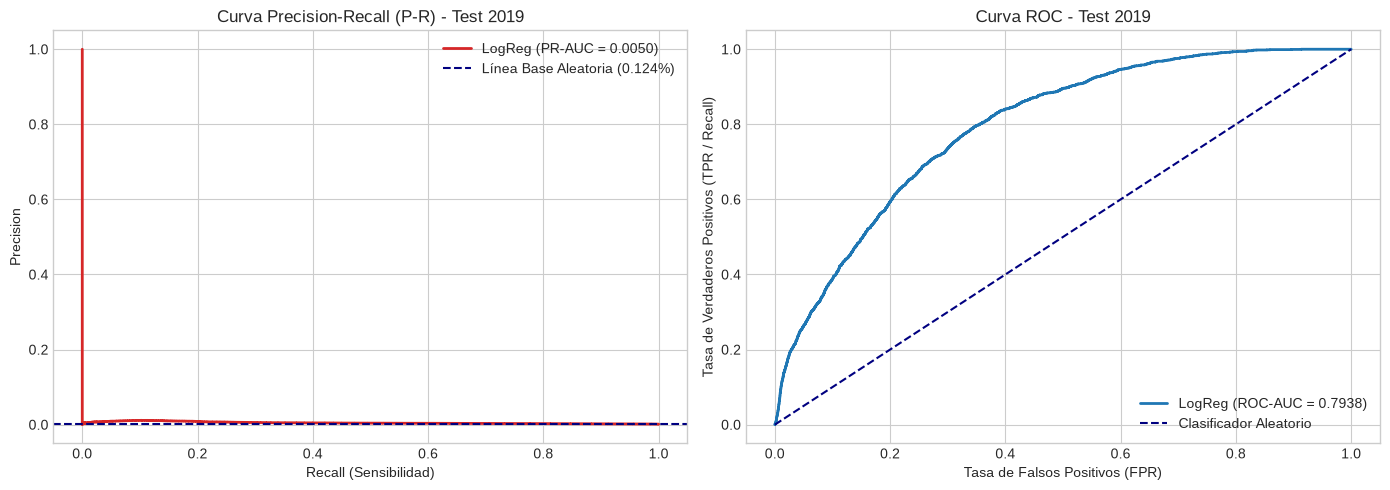

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Curva Precision-Recall
precisions, recalls, thresholds_pr = precision_recall_curve(y_test, y_prob_log)
ax1.plot(recalls, precisions, color="#d62728", lw=2, label=f"LogReg (PR-AUC = {metrics_log['pr_auc']:.4f})")
ax1.axhline(y=test_df['is_fraud'].mean(), color="navy", linestyle="--", label=f"Línea Base Aleatoria ({test_df['is_fraud'].mean()*100:.3f}%)")
ax1.set_xlabel("Recall (Sensibilidad)")
ax1.set_ylabel("Precision")
ax1.set_title("Curva Precision-Recall (P-R) - Test 2019")
ax1.legend(loc="upper right")

# Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_prob_log)
ax2.plot(fpr, tpr, color="#1f77b4", lw=2, label=f"LogReg (ROC-AUC = {metrics_log['roc_auc']:.4f})")
ax2.plot([0, 1], [0, 1], color="navy", linestyle="--", label="Clasificador Aleatorio")
ax2.set_xlabel("Tasa de Falsos Positivos (FPR)")
ax2.set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall)")
ax2.set_title("Curva ROC - Test 2019")
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()


## 6. Evaluación del Modelo Comparativo: Regresión Lineal
Evaluamos el comportamiento de `LinearRegression` al ser forzada a predecir la etiqueta $\{0, 1\}$.


In [7]:
y_pred_lin = lin_reg.predict(X_test_trans)
metrics_lin = compute_regression_metrics(y_test, y_pred_lin)

print("=== Métricas de Regresión Lineal sobre Etiqueta Binaria ===")
print(f"Error Cuadrático Medio (MSE):       {metrics_lin['mse']:.6f}")
print(f"Raíz del Error Cuadrático (RMSE):   {metrics_lin['rmse']:.6f}")
print(f"Error Absoluto Medio (MAE):         {metrics_lin['mae']:.6f}")
print(f"Coeficiente R²:                     {metrics_lin['r2_score']:.6f}")
print(f"Valor Predicho Mínimo:              {metrics_lin['pred_min']:.4f}")
print(f"Valor Predicho Máximo:              {metrics_lin['pred_max']:.4f}")
print(f"Predicciones fuera de [0, 1]:       {metrics_lin['predictions_outside_0_1_count']:,} ({metrics_lin['predictions_outside_0_1_pct']:.2f}%)")


=== Métricas de Regresión Lineal sobre Etiqueta Binaria ===
Error Cuadrático Medio (MSE):       0.001482
Raíz del Error Cuadrático (RMSE):   0.038503
Error Absoluto Medio (MAE):         0.013146
Coeficiente R²:                     -0.197161
Valor Predicho Mínimo:              -0.0291
Valor Predicho Máximo:              0.3843
Predicciones fuera de [0, 1]:       291,672 (17.79%)


### Justificación Teórica y Empírica: ¿Por qué la Regresión Lineal no es adecuada para clasificar fraude?
1. **Predicciones Anómalas fuera del Dominio de Probabilidad:** La función de regresión lineal $y = X\beta$ es una combinación lineal no acotada. Produce valores menores a $0$ y mayores a $1$, los cuales carecen de sentido como probabilidades.
2. **Violación de Supuestos de Homocedasticidad:** En una variable binaria $y \in \{0, 1\}$, la varianza de los residuos es $\text{Var}(y|X) = p(X)(1 - p(X))$, la cual depende directamente de $X$. Los residuos son intrínsecamente heterocedásticos.
3. **Falta de Calibración para la Decisión Humana:** Un analista humano requiere un Risk Score interpretable (e.g. "esta transacción tiene un 85% de probabilidad de fraude"). La regresión lineal no produce estimaciones de probabilidad calibradas.


## 7. Exportación de Resultados
Guardamos el resumen estructurado de evaluación en `artifacts/evaluation_metrics.json`.


In [8]:
evaluation_results = {
    "dataset": "IBM TabFormer - Test Set 2019 (Prevalencia Natural)",
    "total_test_samples": int(len(y_test)),
    "total_frauds": int(np.sum(y_test)),
    "fraud_prevalence_pct": float(np.mean(y_test) * 100),
    "baseline_logistic_regression": metrics_log,
    "comparative_linear_regression": metrics_lin,
}

save_json(evaluation_results, METRICS_ARTIFACT)
print(f"Métricas guardadas exitosamente en: {METRICS_ARTIFACT}")
print(json.dumps(evaluation_results, indent=2))


Métricas guardadas exitosamente en: /home/glender/ProyectosUNi/iaupeu/artifacts/evaluation_metrics.json
{
  "dataset": "IBM TabFormer - Test Set 2019 (Prevalencia Natural)",
  "total_test_samples": 1639673,
  "total_frauds": 2033,
  "fraud_prevalence_pct": 0.12398813665895578,
  "baseline_logistic_regression": {
    "accuracy": 0.7256922569317175,
    "precision": 0.0031977879562562136,
    "recall": 0.7088047220855878,
    "f1_score": 0.006366851722164907,
    "confusion_matrix": {
      "tn": 1188457,
      "fp": 449183,
      "fn": 592,
      "tp": 1441,
      "total": 1639673
    },
    "false_positive_rate": 0.27428677853496497,
    "false_negative_rate": 0.2911952779144122,
    "pr_auc": 0.004999535586026412,
    "roc_auc": 0.7938442776753605
  },
  "comparative_linear_regression": {
    "mse": 0.001482497634966829,
    "rmse": 0.03850321590421804,
    "mae": 0.013145519514987982,
    "r2_score": -0.19716133981815287,
    "pred_min": -0.02912140086760557,
    "pred_max": 0.384326